# Lorenz-63 BSO forecast

A frozen FNO advances the 20 sensor curves. The instantaneous BSO dictionary combines the standardized curve with degree-2 through degree-4 monomials of its leading five PCA coordinates. A ridge-regularized Galerkin map propagates the lifted coefficients autonomously on the held-out trajectory tail.

In [ ]:
import json
import numpy as np

from plotting_utils import print_figure_caption
from project_paths import FIGURES_DIR, RESULTS_DIR as PROJECT_RESULTS_DIR

RESULTS_DIR = PROJECT_RESULTS_DIR / 'l63'
MANIFEST_PATH = RESULTS_DIR / "manifest.json"
FORECAST_PATH = RESULTS_DIR / "forecast_metrics.npz"
numerical_results_available = MANIFEST_PATH.is_file() and FORECAST_PATH.is_file()
metrics = None
times = operator_errors = spectral_errors = None
if numerical_results_available:
    metrics = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
    with np.load(FORECAST_PATH) as stored:
        times = stored["times"]
        operator_errors = stored["operator_errors"]
        spectral_errors = stored["spectral_errors"]
    print(f"FNO mean relative L2: {metrics['mean_relative_l2']['operator']:.4f}")
    print(f"BSO mean relative L2: {metrics['mean_relative_l2']['spectral']:.4f}")
else:
    print("Numerical artifacts are absent; the committed reference figure will be displayed.")

FNO mean relative L2: 1.1101
BSO mean relative L2: 0.9482


The panels show consecutive forecast ranges. The short range uses a logarithmic vertical axis because it spans several orders of magnitude; the later ranges use their own linear scales so the separation between the two forecasts remains visible.

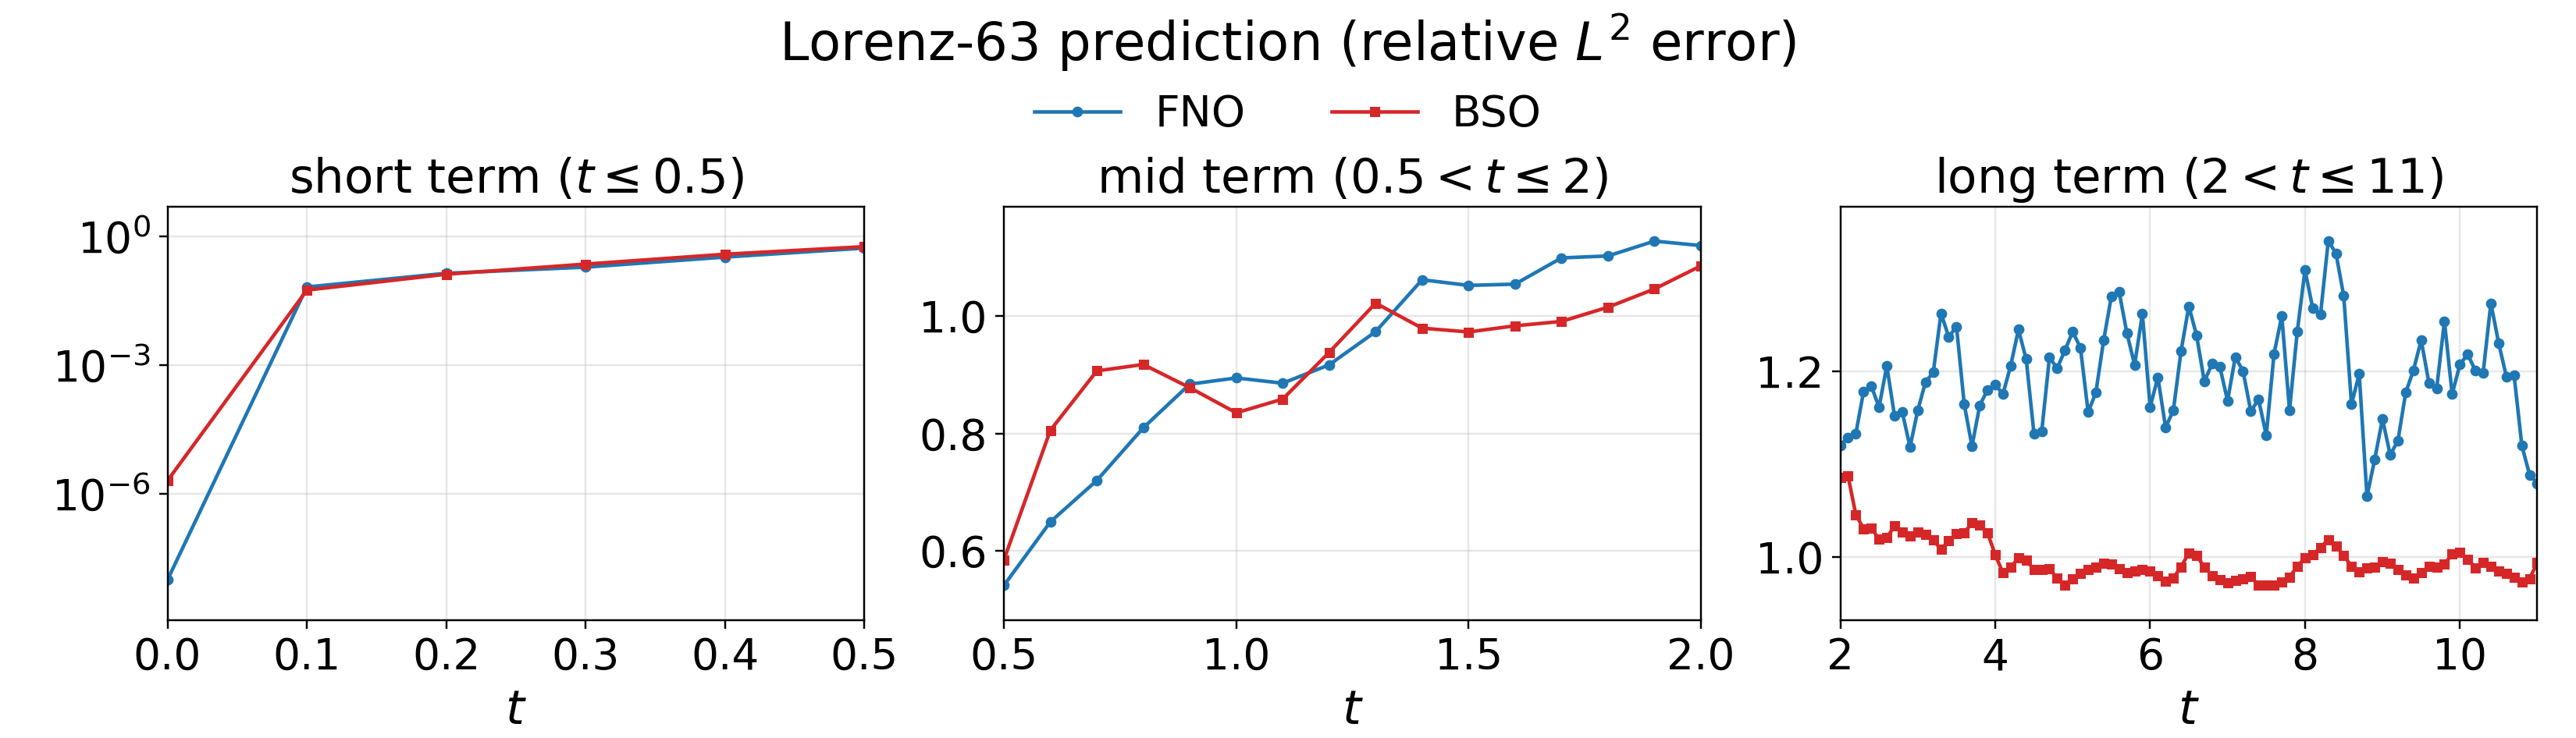


Figure caption:
Pooled relative $L^2$ forecast error over 64 overlapping origins from the held-out Lorenz-63 sensor trajectory. The autoregressive frozen FNO and 140-dimensional polynomial-PCA BSO are shown over short, middle, and long lead panels with independent vertical scales; the short panel is logarithmic. BSO is comparable at short and intermediate leads and has lower long-range mean error.


In [ ]:
from IPython.display import Image, display
from experiments.lorenz63.exp_lorenz63 import plot_forecasts

figure_path = FIGURES_DIR / 'lorenz63' / 'l63_prediction.pdf'
if numerical_results_available:
    plot_forecasts(figure_path, times, operator_errors, spectral_errors)
display(Image(filename=str(figure_path.with_suffix('.png'))))
print_figure_caption(
    "Pooled relative $L^2$ forecast error over 64 overlapping origins from the held-out Lorenz-63 sensor trajectory. The autoregressive frozen FNO and 140-dimensional polynomial-PCA BSO are shown over short, middle, and long lead panels with independent vertical scales; the short panel is logarithmic. BSO is comparable at short and intermediate leads and has lower long-range mean error."
)

In [ ]:
if metrics is None:
    print("Numerical settings and lead errors require the ignored result artifacts.")
else:
    print("Method settings")
    for key, value in metrics["method"].items():
        print(f"  {key}: {value}")
    print("\nReported BSO errors")
    for key, value in sorted(
        metrics["selected_leads"].items(),
        key=lambda item: float(item[0].removeprefix("t")),
    ):
        print(f"  {key}: {value:.4f}")

Method settings
  decoder_ridge_relative: 1e-10
  dictionary: standardized field plus PCA-coordinate monomials
  dictionary_size: 140
  operator: frozen FNO
  pca_coordinates: 5
  polynomial_degree: 4
  projection: ridge-regularized Galerkin least squares
  sampling_stride: 1
  stability_radius: 0.97
  target: frozen FNO one-step image
  training_family: nonlinear_sensor
  transition_ridge_relative: 0.001

Reported BSO errors
  t0: 0.0000
  t0.1: 0.0567
  t0.2: 0.1329
  t0.5: 0.5845
  t2: 1.0856
  t11: 0.9934
